In [2]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
#from utils import *
#from utils_cpdir import *
from utils_experiments import *
from utils_mvcp import *
from utils import *
import os
from tqdm import tqdm

In [3]:
# Reference Libraries

rebecca_data_ir = pd.read_csv('processed_data_new/rebecca_data_ir_final.csv')
del rebecca_data_ir['Unnamed: 0']
rebecca_data_ir.columns = list(np.float64(rebecca_data_ir.columns[:-4])) + list(rebecca_data_ir.columns[-4:])

rebecca_data_raman = pd.read_csv('processed_data_new/rebecca_data_raman_final_specy.csv')
del rebecca_data_raman['Unnamed: 0']
rebecca_data_raman.columns = list(np.float64(rebecca_data_raman.columns[:-4])) + list(rebecca_data_raman.columns[-4:])




poly_abbr_table = pd.read_excel('data_new/CCOPTIR_20240604_MixedMPsStdsv2_RP_mIRage_allccdata_manualsort.xlsx',
         sheet_name='Other cc data and sort').iloc[:9,-5:-3]
poly_abbr_table.columns = ['polymer', 'abbr']

poly_and_comments_list = pd.read_excel('data_new/CCOPTIR_20240604_MixedMPsStdsv2_RP_mIRage_allccdata_manualsort.xlsx',
         sheet_name='Other cc data and sort').iloc[:,9:13]

poly_list = list(np.unique(rebecca_data_raman['polymer'])) + ['LDPE']

IR_spectra_mix_std = pd.read_csv('processed_data_new/data_ir_mix_std_rebecca.csv')
del IR_spectra_mix_std['Unnamed: 0']
#non_bg = IR_spectra['background'] == 'no_background'
IR_spectra_mix_std.columns = list(np.float64(IR_spectra_mix_std.columns[:-8])) + list(IR_spectra_mix_std.columns[-8:])

IR_spectra_mix_std = (IR_spectra_mix_std.
 merge(poly_abbr_table, left_on='polymer', right_on='abbr').
 drop(['polymer_x', 'abbr'],axis=1).
 rename({'polymer_y':'polymer'},axis=1).
iloc[:,list(range(IR_spectra_mix_std.shape[1]-3))+[-1,-3,-2]])

IR_spectra_mix_std_rest = IR_spectra_mix_std.loc[[x not in poly_list for x in IR_spectra_mix_std['polymer']],:].reset_index(drop=True)
#IR_spectra_mix_std = IR_spectra_mix_std.loc[[x in ['LDPE', 'PP', 'PSL'] for x in IR_spectra_mix_std['polymer']],:].reset_index(drop=True)
IR_spectra_mix_std = IR_spectra_mix_std.loc[[x in poly_list for x in IR_spectra_mix_std['polymer']],:].reset_index(drop=True)
IR_spectra_mix_std.loc[IR_spectra_mix_std['polymer'] == 'LDPE','polymer'] = 'PE'
IR_spectra_mix_std = IR_spectra_mix_std.sort_values('id').reset_index(drop=True)



Raman_spectra_mix_std = pd.read_csv('processed_data_new/data_raman_mix_std_rebecca_specy.csv')
#notes_mix_std_rest = np.array(Raman_spectra_mix_std['comments'])
notes_mix_std = Raman_spectra_mix_std.iloc[:,-5:]

notes_mix_std = (notes_mix_std.
                 merge(poly_abbr_table, left_on='polymer', right_on='abbr').
                 drop(['polymer_x', 'abbr'], axis=1).
                 rename({'polymer_y':'polymer_overall'},axis=1).
                 merge(poly_abbr_table, left_on='polymer_raman', right_on='abbr').
                 drop(['polymer_raman', 'abbr'], axis=1).
                 rename({'polymer':'polymer_raman'},axis=1).
                 merge(poly_abbr_table, left_on='polymer_ir', right_on='abbr').
                 drop(['polymer_ir', 'abbr'], axis=1).
                 rename({'polymer':'polymer_ir'},axis=1))

notes_mix_std.loc[notes_mix_std['polymer_overall'] == 'LDPE','polymer_overall'] = 'PE'
notes_mix_std.loc[notes_mix_std['polymer_raman'] == 'LDPE','polymer_raman'] = 'PE'
notes_mix_std.loc[notes_mix_std['polymer_ir'] == 'LDPE','polymer_ir'] = 'PE'


#notes_mix_std_rest[[x is np.nan for x in notes_mix_std_rest]] = ''
del Raman_spectra_mix_std['Unnamed: 0']
Raman_spectra_mix_std.columns = list(np.float64(Raman_spectra_mix_std.columns[:-7])) + list(Raman_spectra_mix_std.columns[-7:])
Raman_spectra_mix_std = (Raman_spectra_mix_std.
 merge(poly_abbr_table, left_on='polymer', right_on='abbr').
 drop(['polymer_x', 'abbr'],axis=1).
 rename({'polymer_y':'polymer'},axis=1).
iloc[:,list(range(Raman_spectra_mix_std.shape[1]-5))+[-1,-2]])

#poly_and_comments_list_rest = poly_and_comments_list.loc[[x not in poly_list for x in Raman_spectra_mix_std['polymer']],:].reset_index(drop=True)

notes_mix_std = notes_mix_std.sort_values('id').reset_index(drop=True)
Raman_spectra_mix_std = Raman_spectra_mix_std.sort_values('id').reset_index(drop=True)

Raman_spectra_mix_std_rest = Raman_spectra_mix_std.loc[[x not in poly_list for x in Raman_spectra_mix_std['polymer']],:].reset_index(drop=True)
notes_mix_std_rest = notes_mix_std.loc[[x not in poly_list for x in Raman_spectra_mix_std['polymer']],:].reset_index(drop=True)

#poly_and_comments_list = poly_and_comments_list.loc[[x in poly_list for x in Raman_spectra_mix_std['polymer']],:].reset_index(drop=True)

notes_mix_std = notes_mix_std.loc[[x in poly_list for x in Raman_spectra_mix_std['polymer']],:].reset_index(drop=True)
Raman_spectra_mix_std = Raman_spectra_mix_std.loc[[x in poly_list for x in Raman_spectra_mix_std['polymer']],:].reset_index(drop=True)

Raman_spectra_mix_std.loc[Raman_spectra_mix_std['polymer'] == 'LDPE','polymer'] = 'PE'

#ids_ideal_set = [(x in poly_list) and (y in poly_list) and (z in poly_list) for x, y, z in zip(notes_mix_std['polymer_raman'], notes_mix_std['polymer_ir'], notes_mix_std['polymer_overall'])]
#Raman_spectra_mix_std = Raman_spectra_mix_std.loc[ids_ideal_set,:].reset_index(drop=True)
#IR_spectra_mix_std = IR_spectra_mix_std.loc[ids_ideal_set,:].reset_index(drop=True)

Raman_spectra_mix_std = Raman_spectra_mix_std.query('id != 223').reset_index(drop=True)
IR_spectra_mix_std = IR_spectra_mix_std.query('id != 223').reset_index(drop=True)

Raman_spectra_mix_std['id'] = ["mix_std_"+str(x) for x in Raman_spectra_mix_std['id']]
IR_spectra_mix_std['id'] = ["mix_std_"+str(x) for x in IR_spectra_mix_std['id']]

poly_abbr_table = pd.read_excel('data_new/CCOPTIR_20240326_MixedMPsv7.3_RP_mIRage_allccdata_manualsort.xlsx',
         sheet_name='Other cc data and sort').iloc[:9,-5:-3]
poly_abbr_table.columns = ['polymer', 'abbr']

poly_and_comments_list = pd.read_excel('data_new/CCOPTIR_20240326_MixedMPsv7.3_RP_mIRage_allccdata_manualsort.xlsx',
         sheet_name='Other cc data and sort').iloc[:,9:13]

poly_list = list(np.unique(rebecca_data_raman['polymer'])) + ['LDPE']

IR_spectra_mix = pd.read_csv('processed_data_new/data_ir_mix_rebecca.csv')
del IR_spectra_mix['Unnamed: 0']
#non_bg = IR_spectra['background'] == 'no_background'
IR_spectra_mix.columns = list(np.float64(IR_spectra_mix.columns[:-8])) + list(IR_spectra_mix.columns[-8:])

IR_spectra_mix = (IR_spectra_mix.
 merge(poly_abbr_table, left_on='polymer', right_on='abbr').
 drop(['polymer_x', 'abbr'],axis=1).
 rename({'polymer_y':'polymer'},axis=1).
iloc[:,list(range(IR_spectra_mix.shape[1]-3))+[-1,-3,-2]])

IR_spectra_mix_rest = IR_spectra_mix.loc[[x not in poly_list for x in IR_spectra_mix['polymer']],:].reset_index(drop=True)
#IR_spectra_mix = IR_spectra_mix.loc[[x in ['LDPE', 'PP', 'PSL'] for x in IR_spectra_mix['polymer']],:].reset_index(drop=True)
IR_spectra_mix = IR_spectra_mix.loc[[x in poly_list for x in IR_spectra_mix['polymer']],:].reset_index(drop=True)
IR_spectra_mix.loc[IR_spectra_mix['polymer'] == 'LDPE','polymer'] = 'PE'
IR_spectra_mix = IR_spectra_mix.sort_values('id').reset_index(drop=True)


#Raman_spectra_mix = pd.read_csv('processed_data_new/data_raman_mix_rebecca.csv')
Raman_spectra_mix = pd.read_csv('processed_data_new/data_raman_mix_rebecca_specy.csv')
#notes_mix_rest = np.array(Raman_spectra_mix['comments'])
notes_mix = Raman_spectra_mix.iloc[:,-5:]

notes_mix = (notes_mix.
                 merge(poly_abbr_table, left_on='polymer', right_on='abbr').
                 drop(['polymer_x', 'abbr'], axis=1).
                 rename({'polymer_y':'polymer_overall'},axis=1).
                 merge(poly_abbr_table, left_on='polymer_raman', right_on='abbr').
                 drop(['polymer_raman', 'abbr'], axis=1).
                 rename({'polymer':'polymer_raman'},axis=1).
                 merge(poly_abbr_table, left_on='polymer_ir', right_on='abbr').
                 drop(['polymer_ir', 'abbr'], axis=1).
                 rename({'polymer':'polymer_ir'},axis=1))

notes_mix.loc[notes_mix['polymer_overall'] == 'LDPE','polymer_overall'] = 'PE'
notes_mix.loc[notes_mix['polymer_raman'] == 'LDPE','polymer_raman'] = 'PE'
notes_mix.loc[notes_mix['polymer_ir'] == 'LDPE','polymer_ir'] = 'PE'


#notes_mix_rest[[x is np.nan for x in notes_mix_rest]] = ''
del Raman_spectra_mix['Unnamed: 0']
Raman_spectra_mix.columns = list(np.float64(Raman_spectra_mix.columns[:-7])) + list(Raman_spectra_mix.columns[-7:])
Raman_spectra_mix = (Raman_spectra_mix.
 merge(poly_abbr_table, left_on='polymer', right_on='abbr').
 drop(['polymer_x', 'abbr'],axis=1).
 rename({'polymer_y':'polymer'},axis=1).
iloc[:,list(range(Raman_spectra_mix.shape[1]-5))+[-1,-2]])

#poly_and_comments_list_rest = poly_and_comments_list.loc[[x not in poly_list for x in Raman_spectra_mix['polymer']],:].reset_index(drop=True)

notes_mix = notes_mix.sort_values('id').reset_index(drop=True)
Raman_spectra_mix = Raman_spectra_mix.sort_values('id').reset_index(drop=True)

Raman_spectra_mix_rest = Raman_spectra_mix.loc[[x not in poly_list for x in Raman_spectra_mix['polymer']],:].reset_index(drop=True)
notes_mix_rest = notes_mix.loc[[x not in poly_list for x in Raman_spectra_mix['polymer']],:].reset_index(drop=True)

#poly_and_comments_list = poly_and_comments_list.loc[[x in poly_list for x in Raman_spectra_mix['polymer']],:].reset_index(drop=True)

notes_mix = notes_mix.loc[[x in poly_list for x in Raman_spectra_mix['polymer']],:].reset_index(drop=True)
Raman_spectra_mix = Raman_spectra_mix.loc[[x in poly_list for x in Raman_spectra_mix['polymer']],:].reset_index(drop=True)

Raman_spectra_mix.loc[Raman_spectra_mix['polymer'] == 'LDPE','polymer'] = 'PE'

Raman_spectra_mix['id'] = ["mix_"+str(x) for x in Raman_spectra_mix['id']]
IR_spectra_mix['id'] = ["mix_"+str(x) for x in IR_spectra_mix['id']]

#ids_ideal_set = [(x in poly_list) and (y in poly_list) and (z in poly_list) for x, y, z in zip(notes_mix['polymer_raman'], notes_mix['polymer_ir'], notes_mix['polymer_overall'])]
#Raman_spectra_mix = Raman_spectra_mix.loc[ids_ideal_set,:].reset_index(drop=True)
#IR_spectra_mix = IR_spectra_mix.loc[ids_ideal_set,:].reset_index(drop=True)


IR_spectra_all = pd.concat([IR_spectra_mix_std, IR_spectra_mix], axis=0).reset_index(drop=True)
Raman_spectra_all = pd.concat([Raman_spectra_mix_std, Raman_spectra_mix], axis=0).reset_index(drop=True)

lower_range_raman_1 = 600
upper_range_raman_1 = 1850
lower_range_raman_2 = 2750
upper_range_raman_2 = 3500

wn_raman = np.array(Raman_spectra_all.columns[:-4])

idx_raman = list(np.logical_or(np.logical_and(wn_raman >lower_range_raman_1,
                           wn_raman <upper_range_raman_1
                           ),
                 np.logical_and(wn_raman >lower_range_raman_2,
                           wn_raman <upper_range_raman_2
                           ))) + [True]*4


(x_train_ir, x_train_raman, 
 label_train_IR, label_train_Raman, 
 x_ir, x_raman, 
 label_ir, label_raman, label_table, ids_test) = process_data(
    rebecca_data_ir,                                                                             
    rebecca_data_raman.loc[:, idx_raman],                                                                                   
    IR_spectra_all,                                                                               
    Raman_spectra_all.loc[:, idx_raman]
)


# Data Experiments Figure 2
smx_all_IR = 1-np.power(smx_nn(x_train_ir, x_ir, label_train_IR, tau=1.4427),1)
smx_all_Raman = 1-np.power(smx_nn(x_train_raman, x_raman, label_train_Raman, tau=1.4427),1)
score_list = [smx_all_IR, smx_all_Raman]

smx_all_IR_all = 1-np.power(smx_nn_all(x_train_ir, x_ir, label_train_IR),1)
smx_all_Raman_all = 1-np.power(smx_nn_all(x_train_raman, x_raman, label_train_Raman),1)
score_all_list = [smx_all_IR_all, smx_all_Raman_all]

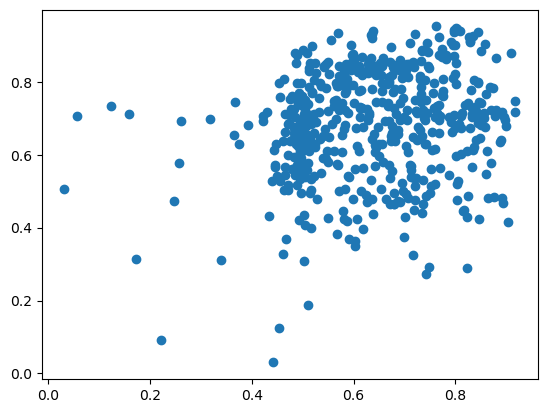

In [20]:
plt.scatter(1-smx_all_IR[np.arange(label_ir.shape[0]), label_ir],
            1-smx_all_Raman[np.arange(label_ir.shape[0]), label_ir])

In [17]:
x_ir.shape

(530, 525)

In [15]:
IR_spectra_all.iloc[:,:-8].shape

(530, 535)

In [3]:
IR_spectra_mix.columns[:-10][np.float64(IR_spectra_mix.columns[:-10])>2718]

Index([2721.0, 2723.0, 2725.0, 2727.0, 2729.0, 2731.0, 2733.0, 2735.0, 2737.0,
       2739.0,
       ...
       2947.0, 2949.0, 2951.0, 2953.0, 2955.0, 2957.0, 2959.0, 2961.0, 2963.0,
       2965.0],
      dtype='object', length=123)

In [4]:
Raman_spectra_mix = pd.read_csv('processed_data_new/data_raman_mix_rebecca_specy.csv')
del Raman_spectra_mix['Unnamed: 0']
Raman_spectra_mix.columns = list(np.float64(Raman_spectra_mix.columns[:-7])) + list(Raman_spectra_mix.columns[-7:])

IR_spectra_mix = pd.read_csv('processed_data_new/data_ir_mix_rebecca.csv')
del IR_spectra_mix['Unnamed: 0']
#non_bg = IR_spectra['background'] == 'no_background'
IR_spectra_mix.columns = list(np.float64(IR_spectra_mix.columns[:-8])) + list(IR_spectra_mix.columns[-8:])

IR_spectra_mix.query('id==53').iloc[:,:-8]

,981.0,983.0,985.0,987.0,989.0,991.0,993.0,995.0,997.0,999.0,...,2951.0,2953.0,2955.0,2957.0,2959.0,2961.0,2963.0,2965.0,2967.0,2969.0
52,-1.731391,-2.738848,-2.25146,-2.11931,-1.571744,-0.850662,-1.191301,-1.489497,-0.653232,-0.01582,...,-1.706966,-0.0363,2.203625,0.166376,-4.023154,-5.069104,-6.706874,-6.675238,-5.597579,-4.927053


100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:09<00:00,  9.76s/it]


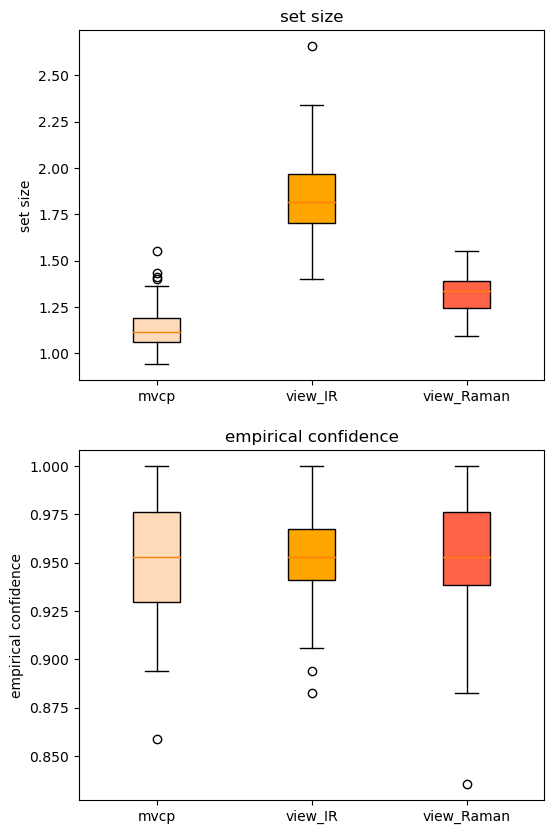

In [5]:
N_sim = 100

# Figure 3b

(df_res_lis, 
 df_res_sd_lis, 
 df_res_cov_lis, 
 df_res_cov_sd_lis, 
 df_res_all_mean_lis, 
 df_res_cov_all_mean_lis,
 df_res_all_lis, 
 df_res_cov_all_lis,
 df_res_labels_all,
 df_res_pred_set_all_lis)  = experiment_fig_1_2(score_list,                                      
                                           label_ir,                                   
                                           [0.05],                                 
                                           N_sim,                          
                                           quant_prop=.2,                         
                                           cal_prop=0.8, 
                                           seed_init=0)
          

fig, ax = plt.subplots(nrows=2, figsize=(6, 10))
title = ['none', 'low', 'medium', 'high']
set_size = [np.array(df_res_all_mean_lis[0][x]) for x in df_res_all_mean_lis[0]]
cov = [np.array(df_res_cov_all_mean_lis[0][x]) for x in df_res_cov_all_mean_lis[0]]


labels = list(df_res_all_mean_lis[0].keys())
colors = ['peachpuff', 'orange', 'tomato']

ax[0].set_ylabel('set size')
ax[0].set_title('set size')

bplot = ax[0].boxplot(set_size,
                       patch_artist=True,
                       labels=labels)  # will be used to label x-ticks

    # fill with colors
for patch, color in zip(bplot['boxes'], colors):
    patch.set_facecolor(color)
    
    
labels = list(df_res_cov_all_mean_lis[0].keys())   
ax[1].set_ylabel('empirical confidence')
ax[1].set_title('empirical confidence')

bplot = ax[1].boxplot(cov,
                       patch_artist=True,
                       labels=labels)  # will be used to label x-ticks

    # fill with colors
for patch, color in zip(bplot['boxes'], colors):
    patch.set_facecolor(color)

plt.show()             

In [ ]:
from datetime import date

# Get the current date
todays_date = date.today()
print("Today's date =", todays_date)
#todays_date.


In [ ]:
from datetime import date

# Get the current date
todays_date = date.today()
year = str(todays_date.year)
if todays_date.month < 10:
    month = '0'+str(todays_date.month)
else:
    month = str(todays_date.month)

if todays_date.day < 10:
    day = '0'+str(todays_date.day)
else:
    day = str(todays_date.day)

year+month+day

In [ ]:
np.unique(df_res_labels_all[0][0])

In [ ]:
for method in ['mvcp', 'view_IR', 'view_Raman']:
    table_SI_2 = pd.merge(pd.concat([pd.DataFrame({'label':np.where(x)[1],
     'n':1}).groupby('label').sum() for x in df_res_pred_set_all_lis[0][method]], axis=1).mean(1).reset_index(),
    pd.concat([pd.DataFrame({'label':x, 'n':1}).groupby('label').sum() for x in df_res_labels_all[0]], axis=1).mean(1).reset_index(), on='label').merge(
    label_table, on='label')
    table_SI_2.columns = ['label', 'number_label_in_pred_sets', 'number_label', 'polymer']
    table_SI_2.to_csv('results_final/data_fig_SI_2_'+method+'.csv')

In [ ]:

for method in ['mvcp', 'view_IR', 'view_Raman']:
    table_SI_2 = pd.merge(pd.concat([pd.DataFrame({'label':np.where(x)[1],
     'n':1}).groupby('label').sum() for x in df_res_pred_set_all_lis[0][method]], axis=1).mean(1).reset_index(),
    pd.concat([pd.DataFrame({'label':x, 'n':1}).groupby('label').sum() for x in df_res_labels_all[0]], axis=1).mean(1).reset_index(), on='label').merge(
    label_table, on='label')
    table_SI_2.columns = ['label', 'number_label_in_pred_sets', 'number_label', 'polymer']
    x = range(table_SI_2.shape[0])
    width = 0.35
    plt.figure(figsize=(7,4))
    plt.bar([xi - width/2 for xi in x], 
            table_SI_2["number_label_in_pred_sets"], 
            width=width, 
            label="number_label_in_pred_sets")

    plt.bar([xi + width/2 for xi in x], 
            table_SI_2["number_label"], 
            width=width, 
            label="number_label")

    plt.xticks(x, table_SI_2["polymer"])
    plt.title(method)
    plt.xlabel("label")
    plt.ylabel("Value")
    plt.legend()
    plt.tight_layout()
    plt.show()

In [ ]:

for method in ['mvcp', 'view_IR', 'view_Raman']:
    table_SI_2 = pd.merge(pd.concat([pd.DataFrame({'label':np.where(x)[1],
     'n':1}).groupby('label').sum() for x in df_res_pred_set_all_lis[0][method]], axis=1).mean(1).reset_index(),
    pd.concat([pd.DataFrame({'label':x, 'n':1}).groupby('label').sum() for x in df_res_labels_all[0]], axis=1).mean(1).reset_index(), on='label').merge(
    label_table, on='label')
    table_SI_2.columns = ['label', 'number_label_in_pred_sets', 'number_label', 'polymer']
    x = range(table_SI_2.shape[0])
    width = 0.35
    plt.figure(figsize=(7,4))
    plt.bar([xi - width/2 for xi in x], 
            table_SI_2["number_label_in_pred_sets"], 
            width=width, 
            label="number_label_in_pred_sets")

    plt.bar([xi + width/2 for xi in x], 
            table_SI_2["number_label"], 
            width=width, 
            label="number_label")

    plt.xticks(x, table_SI_2["polymer"])
    plt.title(method)
    plt.xlabel("label")
    plt.ylabel("Value")
    plt.legend()
    plt.tight_layout()
    plt.show()

In [ ]:
method = 'mvcp'
table_fig2d_list = []

table_fig2d_aux = pd.DataFrame(np.zeros((6,3)))
table_fig2d_aux.columns = ['number of spectra', 
                               'correct label in prediction set', 
                               'correct label not in prediction set']

set_size_list_df = pd.DataFrame({'labels':np.arange(6)})
set_size_list_df

n = len(df_res_all_lis[0][method])
for df_ss, df_cov, df_labels in zip(df_res_all_lis[0][method], df_res_cov_all_lis[0][method], df_res_labels_all[0]):
    table_fig2d = pd.DataFrame({'labels':df_labels,
                                'set_size':df_ss,
                                    'cov':df_cov})

    table_fig2d = pd.concat([table_fig2d.groupby('labels').count()['set_size'],
                                 table_fig2d.groupby('labels').mean()['cov'],
                                 1-table_fig2d.groupby('labels').mean()['cov']], axis=1)

    table_fig2d.columns = ['number of spectra', 
                               'correct label in prediction set', 
                               'correct label not in prediction set']
        
    table_fig2d = table_fig2d.reset_index()
    table_fig2d = pd.merge(set_size_list_df, 
                               table_fig2d, 
                               on='labels', how='left')
    table_fig2d[np.isnan(table_fig2d)] = 0
    table_fig2d_aux = table_fig2d_aux + table_fig2d.iloc[:,1:]
    table_fig2d_list.append(table_fig2d)

table_fig2d_aux = table_fig2d_aux / np.array([np.array([n]*6),
              np.array(sum([df.iloc[:,2:].sum(1) for df in table_fig2d_list])),
              np.array(sum([df.iloc[:,2:].sum(1) for df in table_fig2d_list]))]).T

table_fig2d_aux['labels'] = range(6)
table_fig2d_aux = table_fig2d_aux.set_index('labels')

table_fig2d_aux_std = pd.DataFrame(np.sqrt(np.sum([np.array(1*(x.iloc[:,1]>0))[:,None]*(x.iloc[:,1:]-table_fig2d_aux)**2 for x in table_fig2d_list], 0)/
                         np.array([np.array([n]*6),
                                   np.array(sum([df.iloc[:,2:].sum(1) for df in table_fig2d_list])),
                                   np.array(sum([df.iloc[:,2:].sum(1) for df in table_fig2d_list]))]).T))

table_fig2d_aux_std.columns = table_fig2d_aux.columns

table_fig2d_aux_std['labels'] = range(6)
table_fig2d_aux_std = table_fig2d_aux_std.set_index('labels')
table_fig2d_aux_std.columns = [x+' (standard deviation)' for x in table_fig2d_aux_std.columns]

table_fig2d_aux.columns = [x+' (mean)' for x in table_fig2d_aux.columns]

table_fig2d_aux

In [ ]:
pd.DataFrame({'labels':df_labels,
                                'set_size':df_ss,
                                    'cov':df_cov})

In [ ]:
table_fig2d_aux/100

In [ ]:
np.int64(np.mean(table_fig2d_list, 0))

In [ ]:
table_fig2d#.sum()

In [ ]:
df_res_lis, 
 df_res_sd_lis, 
 df_res_cov_lis, 
 df_res_cov_sd_lis, 
 df_res_all_mean_lis, 
 df_res_cov_all_mean_lis,
 df_res_all_lis, 
 df_res_cov_all_lis

In [ ]:
df_res_lis, df_res_sd_lis

In [ ]:
(np.mean(df_res_all_mean_lis[0]['mvcp']),
 np.std(df_res_all_mean_lis[0]['mvcp']))

In [ ]:
np.mean(df_res_all_lis[0]['mvcp'])

In [ ]:
np.sqrt(np.sum([np.std(x)**2 for x in df_res_all_lis[0]['mvcp']]))

In [ ]:
np.std(df_res_all_lis[0]['mvcp'])

In [ ]:
df_res_all_lis

In [ ]:
(ps_list, 
 ps_ir_list, 
 ps_raman_list, 
 env_list, 
 cal_smx_arr, 
 cal_idx_list, 
 q_ir_list, 
 q_raman_list) = envelop_2(score_list, label_ir,
                         alphas=[0.05],
                         label_table=label_table,
                         N_sim=1, 
                         quant_prop=.2, 
                         cal_prop=0.8, 
                         seed_init=0)
cal_smx_arr_list = [score_list[0][~x[0]][x[1]] for x in cal_idx_list[5]]

In [ ]:
# Figure 1

id_ = 519#116
example_id = IR_spectra_all.iloc[id_,-2]
score_example = [score_list[0][id_:id_+1], score_list[1][id_:id_+1]]

(ps_list, 
 ps_ir_list, 
 ps_raman_list, 
 env_list, 
 cal_smx_arr, 
 cal_idx_list, 
 q_ir_list, 
 q_raman_list,
 beta_list) = envelop(score_list, label_ir, score_example,
                         alphas=[0.40,.20, .10, 0.05, 0.02],
                         label_table=label_table,
                         N_sim=1, 
                         quant_prop=.2, 
                         cal_prop=0.8, 
                         seed_init=0)

In [4]:
# Figure 1

id_ = 519#116
example_id = IR_spectra_all.iloc[id_,-2]
score_example = [score_list[0][id_:id_+1], score_list[1][id_:id_+1]]

(ps_list, 
 ps_ir_list, 
 ps_raman_list, 
 env_list, 
 cal_smx_arr, 
 cal_idx_list, 
 q_ir_list, 
 q_raman_list,
 beta_list,
 t_list,
 q_array_list) = envelop_3(score_list, label_ir, score_example,
                         alphas=[0.40,.20, .10, 0.05, 0.02],
                         label_table=label_table,
                         N_sim=1, 
                         quant_prop=.2, 
                         cal_prop=0.8, 
                         seed_init=0)

100%|█████████████████████████████████████████████| 5/5 [00:01<00:00,  3.92it/s]


In [8]:
t_list[5][0][1]

1.0215972450664594

In [7]:
K = 2
U_list = gen_u(K, n_th=400, seed=0)

In [ ]:
[ 48,  75,  96, 150, 180, 233, 350]

In [49]:
idx_quant = cal_idx_list[20][0][0]
idx = cal_idx_list[20][0][1]

score_list_cal = [score_list[0][~idx_quant][idx],
                  score_list[1][~idx_quant][idx]]
label_list_cal = label_ir[~idx_quant][idx]

score_list_quant = [score_list[0][idx_quant],
                  score_list[1][idx_quant]]
label_list_quant = label_ir[idx_quant]

quant_smx_arr = np.array(score_list_quant)[:,
                         np.arange(label_list_quant.shape[0]),                           
                         label_list_quant]

In [ ]:
np.argmin(np.abs(np.arccos(U_list[0])[:,0] - np.pi/6))

In [ ]:
np.where(np.logical_and(score_list_cal_projected>0.70305233,
                        score_list_cal_projected<0.72305233))[0]

In [ ]:
np.argsort(score_list_cal_projected)

In [24]:
env_raw = np.array([u*q_array_list[5][0][i] for i, u in enumerate(U_list[0])])

In [238]:
(1-q_ir_list[5][0], 
1-q_raman_list[5][0])

(0.4448051413153097, 0.4224152165427615)

(-0.01, 1.01)

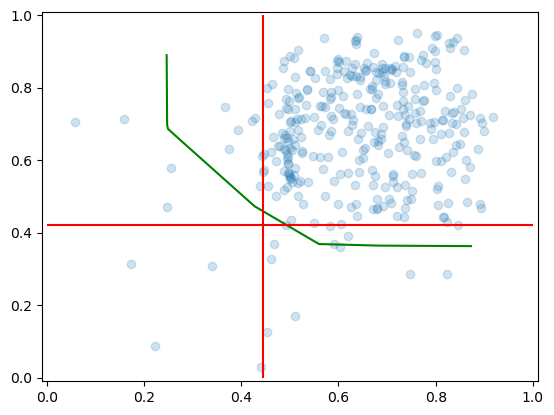

In [241]:
plt.plot(1-env_list[5][0][0], 
         1-env_list[5][0][1], color='green', label='raw')

plt.scatter(1-cal_smx_arr[0,:],
                1-cal_smx_arr[1,:], alpha=.2)

plt.vlines(1-q_ir_list[5][0], 0, 1, 'red')
plt.hlines(1-q_raman_list[5][0], 0, 1, 'red')

plt.xlim(-.01,1.01)
plt.ylim(-.01,1.01)

In [250]:
(np.sum(np.logical_and(
    (1-cal_smx_arr[0,:]<1-q_ir_list[5][0]),
    (1-cal_smx_arr[1,:]>1-q_raman_list[5][0]))),
np.sum(np.logical_and(
    (1-cal_smx_arr[0,:]>1-q_ir_list[5][0]),
    (1-cal_smx_arr[1,:]<1-q_raman_list[5][0]))),
np.sum(np.logical_and(
    (1-cal_smx_arr[0,:]<1-q_ir_list[5][0]),
    (1-cal_smx_arr[1,:]<1-q_raman_list[5][0]))),
np.sum(np.logical_and(
    (1-cal_smx_arr[0,:]>1-q_ir_list[5][0]),
    (1-cal_smx_arr[1,:]>1-q_raman_list[5][0]))))

(11, 11, 4, 311)

In [262]:
(np.sum(1-t_list[5][0][0]>1-t_list[5][0][1]),
np.sum(1-t_list[5][0][0]<1-t_list[5][0][1]))


(323, 15)

### Figure Env panel - A

(-0.01, 1.01)

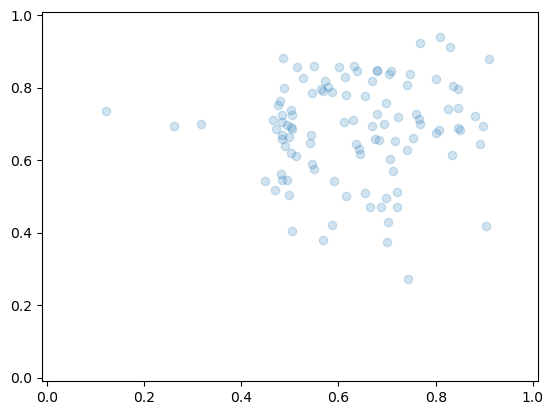

In [216]:
plt.scatter(1-quant_smx_arr[0,:],
                1-quant_smx_arr[1,:], alpha=.2)

plt.xlim(-.01,1.01)
plt.ylim(-.01,1.01)

In [218]:
df_calibration_20 = pd.DataFrame(
    np.array([
        1-quant_smx_arr[0,:],
        1-quant_smx_arr[1,:]
    ]).T)
df_calibration_20.columns = ['IR', 'Raman']
df_calibration_20.to_csv('results_final/20251210/data_fig_calibration_a.csv')

### Figure Env panel - B

77 0.7402487450337502


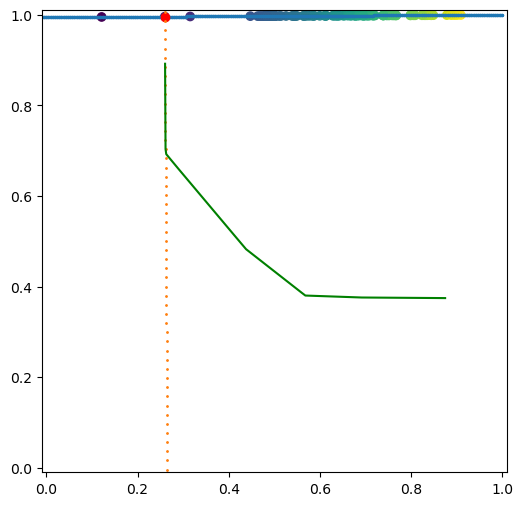

64 0.7631826772544261


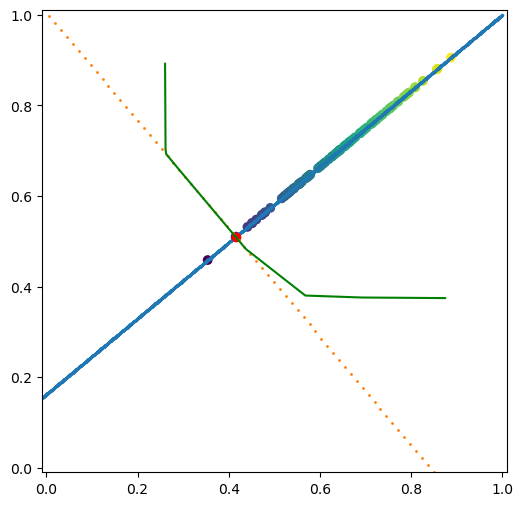

58 0.7542972665032954


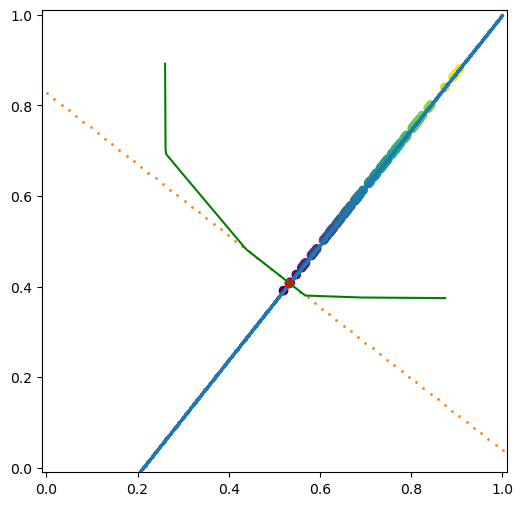

60 0.6261645318745394


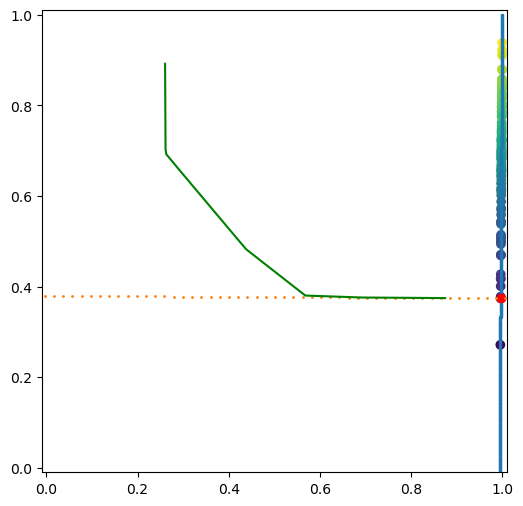

In [401]:

df_projections = pd.DataFrame()
df_orth_list = [] 
df_orth = pd.DataFrame()

for l in [180, 350, 150, 48]: #233 #75, 96
    #print(l)
    plt.figure(figsize=(6, 6))

    plt.plot(1-env_list[5][0][0]/t_list[5][0][1], 
             1-env_list[5][0][1]/t_list[5][0][1], color='green', label='raw')

    score_list_quant_projected = project_u_mv(score_list_quant, U_list[0][l])[0][np.arange(label_list_quant.shape[0]),
                                                    label_list_quant]

    u_theta = U_list[0][l][:,None]
    score_list_quant_projected_vect = (u_theta*score_list_quant_projected).T

    n = score_list_quant_projected.shape[0]
    beta = beta_list[5][0]
    q_level = np.clip(np.ceil((n+1)*(1-beta))/n, 0, 1)
    quant_proj = np.quantile(score_list_quant_projected, q_level, method='higher')
    
    id_point = np.where(score_list_quant_projected == quant_proj)[0][0]
    print(id_point, quant_proj)
    #plt.figure(figsize=(6, 6))

    #plt.scatter(1-quant_smx_arr[0,:],
    #            1-quant_smx_arr[1,:], alpha=.2)
    #plt.scatter(1-u_theta[0],
    #            1-u_theta[1])
    
    plt.scatter(1-score_list_quant_projected_vect[:,0],
                1-score_list_quant_projected_vect[:,1],
                c=np.linalg.norm(1-score_list_quant_projected_vect, axis=1)/np.sqrt(2))
    
    plt.scatter(1-u_theta[0]*np.linspace(0,1.5,1000),
                1-u_theta[1]*np.linspace(0,1.5,1000),
                s=2)
    
    plt.scatter(1-score_list_quant_projected_vect[id_point,0],
                1-score_list_quant_projected_vect[id_point,1],
                color='red')
    
    orth_vect = np.array([score_list_quant_projected_vect[id_point,0],
    score_list_quant_projected_vect[id_point,1]])[:,None] + (np.concatenate([-u_theta[1],u_theta[0]])[:,None]*np.linspace(-1,1, 100))


    plt.scatter(1-orth_vect[0,:],
                1-orth_vect[1,:], s=1)
    
    df_aux = pd.DataFrame(1-score_list_quant_projected_vect)
    df_aux.columns = ['IR - '+str(l), 'Raman - '+str(l)]
    df_aux['threshold_'+str(l)] = 0
    df_aux.iloc[id_point,2] = 1
    df_projections = pd.concat([df_projections, df_aux], axis=1)
    
    df_aux = pd.DataFrame(1-orth_vect.T)
    df_aux.columns = ['IR', 'Raman']
    df_aux = df_aux.query('IR>0 and IR < 1 and Raman >0 and Raman < 1').reset_index(drop=True)
    df_aux.columns = ['IR - '+str(l), 'Raman - '+str(l)]
    df_orth_list.append(df_aux)
    #df_orth = pd.concat([df_orth, df_aux], axis=1)
    
    plt.xlim(-.01,1.01)
    plt.ylim(-.01,1.01)
    #plt.show()
    
    
    plt.show()

In [407]:
df_orth = pd.concat(df_orth_list, axis=1)
df_orth.to_csv('results_final/20251210/data_fig_calibration_b_orthogonal.csv')

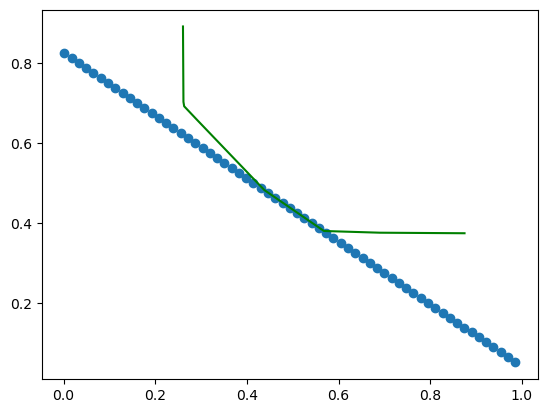

In [406]:
plt.plot(
    1-env_list[5][0][0]/t_list[5][0][1], 
    1-env_list[5][0][1]/t_list[5][0][1], color='green', label='raw')

plt.scatter(
    df_orth['IR - 150'],
    df_orth['Raman - 150']
)


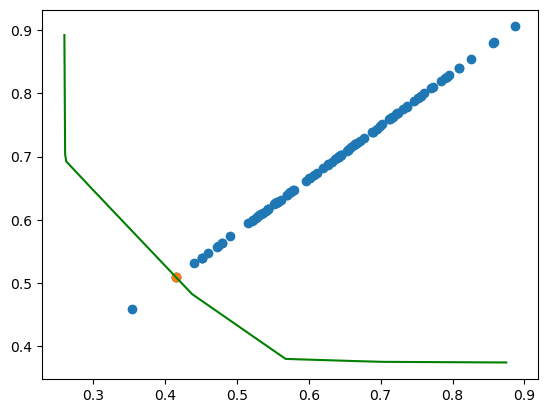

In [274]:
plt.plot(
    1-env_list[5][0][0]/t_list[5][0][1], 
    1-env_list[5][0][1]/t_list[5][0][1], color='green', label='raw')

plt.scatter(
    df_projections['IR - 350'],
    df_projections['Raman - 350']
)


plt.scatter(
    df_projections.query('threshold_350 == 1')['IR - 350'],
    df_projections.query('threshold_350 == 1')['Raman - 350']
)



In [275]:
df_projections.to_csv('results_final/20251210/data_fig_calibration_b.csv')

### Figure Env panel - C

In [279]:
l = 350
score_list_quant_projected = project_u_mv(score_list_quant, U_list[0][l])[0][np.arange(label_list_quant.shape[0]),
                                                    label_list_quant]
u_theta = U_list[0][l][:,None]
score_list_quant_projected_vect = (u_theta*score_list_quant_projected).T

In [280]:
((np.linalg.norm(1-score_list_quant_projected_vect, axis=1)/np.sqrt(2)).min(),
(np.linalg.norm(1-score_list_quant_projected_vect, axis=1)/np.sqrt(2)).max())

(0.40952474572888103, 0.8964156963844195)

In [281]:
np.quantile(np.linalg.norm(1-score_list_quant_projected_vect, axis=1)/np.sqrt(2),
            q_level1-0/(1+n))

0.4971346157984644

In [282]:
n = score_list_quant_projected.shape[0]
beta = beta_list[5][0]
q_level = np.clip(np.ceil((n+1)*(1-beta))/n, 0, 1)
quant_proj = np.quantile(score_list_quant_projected, q_level, method='higher')
1-quant_proj

0.23681732274557388

In [283]:
bins_min, bins_max

(0.27134261157665507, 0.9382714449969011)

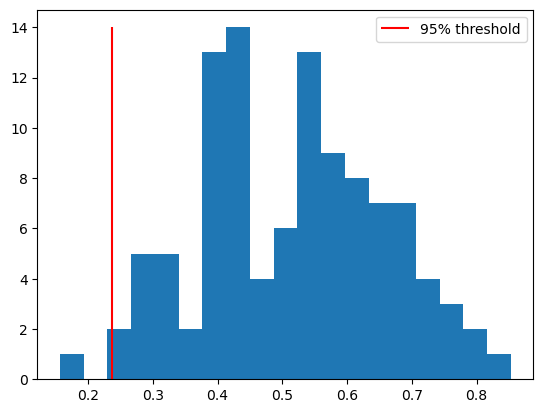

In [289]:
bins_min = np.min(1-score_list_quant_projected)
bins_max = np.max(1-score_list_quant_projected)
bins_list = np.linspace(bins_min, bins_max, 20)

hist_quant_proj = plt.hist(1-score_list_quant_projected, bins=bins_list)
plt.vlines(1-quant_proj, 0, 14, 'red', label='95% threshold')
plt.legend()

In [285]:
np.where((1-score_list_quant_projected) == (1-quant_proj))

(array([64]),)

In [287]:
(1-quant_proj)

0.23681732274557388

In [286]:
df_histogram = pd.DataFrame({'HQI beg bin':hist_quant_proj[1][:-1], 
              'HQI end bin':hist_quant_proj[1][1:], 
              '#':hist_quant_proj[0]
              })
df_histogram#.to_csv('results_final/20251210/data_fig_calibration_c.csv')

,HQI beg bin,HQI end bin,#
0,0.156913,0.193542,1.0
1,0.193542,0.230172,0.0
2,0.230172,0.266801,2.0
3,0.266801,0.303431,5.0
4,0.303431,0.340060,5.0
5,0.340060,0.376690,2.0
6,0.376690,0.413319,13.0
7,0.413319,0.449949,14.0
8,0.449949,0.486578,4.0
9,0.486578,0.523208,6.0


### Figure Env panel - D

(-0.01, 1.01)

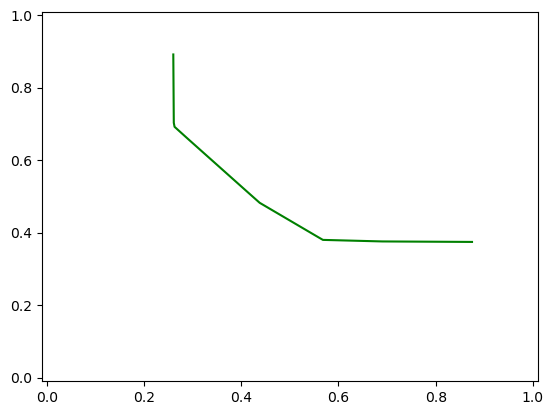

In [232]:
plt.plot(1-env_list[5][0][0]/t_list[5][0][1], 
         1-env_list[5][0][1]/t_list[5][0][1], color='green', label='raw')

plt.xlim(-.01,1.01)
plt.ylim(-.01,1.01)

In [233]:
df_env = pd.DataFrame({
    'IR':1-env_list[5][0][0]/t_list[5][0][1], 
    'Raman':1-env_list[5][0][1]/t_list[5][0][1]
})
df_env.to_csv('results_final/20251210/data_fig_calibration_d.csv')

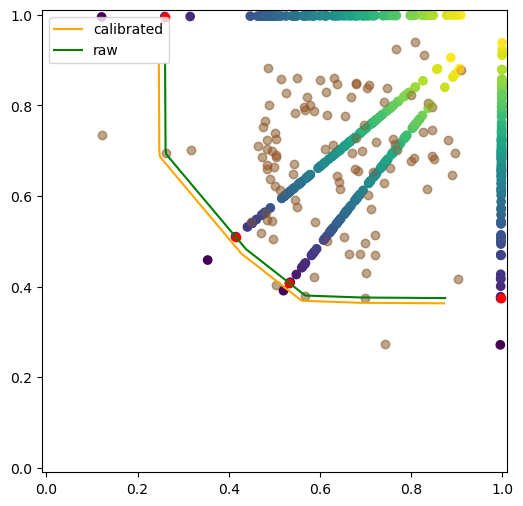

In [290]:
plt.figure(figsize=(6, 6))
plt.plot(1-env_list[5][0][0], 
         1-env_list[5][0][1], color='orange', label='calibrated')
plt.plot(1-env_list[5][0][0]/t_list[5][0][1], 
         1-env_list[5][0][1]/t_list[5][0][1], color='green', label='raw')
    
plt.legend()
df = pd.DataFrame()
for l in [180, 350, 150, 48]: #233 #75, 96
    #print(l)
    score_list_quant_projected = project_u_mv(score_list_quant, U_list[0][l])[0][np.arange(label_list_quant.shape[0]),
                                                    label_list_quant]

    u_theta = U_list[0][l][:,None]
    score_list_quant_projected_vect = (u_theta*score_list_quant_projected).T
    
    n = score_list_quant_projected.shape[0]
    beta = beta_list[5][0]
    q_level = np.clip(np.ceil((n+1)*(1-beta))/n, 0, 1)
    quant_proj = np.quantile(score_list_quant_projected, q_level, method='higher')
    
    id_point = np.where(score_list_quant_projected == quant_proj)[0][0]
    

    #plt.figure(figsize=(6, 6))

    plt.scatter(1-quant_smx_arr[0,:],
                1-quant_smx_arr[1,:], alpha=.2)
    #plt.scatter(1-u_theta[0],
    #            1-u_theta[1])

    plt.scatter(1-score_list_quant_projected_vect[:,0],
                1-score_list_quant_projected_vect[:,1],
                c=np.linalg.norm(1-score_list_quant_projected_vect, axis=1)/np.sqrt(2))
    
    plt.scatter(1-score_list_quant_projected_vect[id_point,0],
                1-score_list_quant_projected_vect[id_point,1],
                color='red')
    
    df_aux = pd.DataFrame(1-score_list_cal_projected_vect)
    df_aux.columns = ['IR - '+str(l), 'Raman - '+str(l)]
    df_aux['threshold - '+str(l)] = 0
    df_aux.iloc[id_point,2] = 1
    df = pd.concat([df, df_aux], axis=1)

    plt.xlim(-.01,1.01)
    plt.ylim(-.01,1.01)
    #plt.show()

(339,)

In [315]:
cov_list = []
for l in range(400):#[48, 150, 180, 233, 350]: #75, 96
    #print(l)
    score_list_cal_projected = project_u_mv(score_list_cal, U_list[0][l])[0][np.arange(label_list_cal.shape[0]),
                                                    label_list_cal]
    
    qhat = q_array_list[5][0][l]
    
    cov_list.append(score_list_cal_projected <= qhat*t_list[5][0][1])

In [314]:
np.prod(cov_list,0).sum()/score_list_cal_projected.shape[0]

0.9498525073746312

In [316]:
np.prod(cov_list,0).sum()/score_list_cal_projected.shape[0]

0.9557522123893806

In [323]:
np.mean(t_list[5][0][0] <= t_list[5][0][1] )

0.9557522123893806

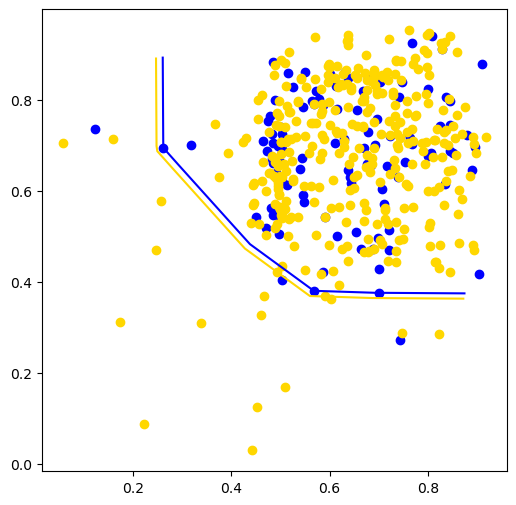

In [300]:
plt.figure(figsize=(6, 6))

plt.plot(1-env_list[5][0][0]/t_list[5][0][1], 
         1-env_list[5][0][1]/t_list[5][0][1], color='blue', label='raw')

plt.plot(1-env_list[5][0][0], 
         1-env_list[5][0][1], color='gold', label='calibrated')

plt.scatter(df_calibration_20.loc[:, 'IR'],
df_calibration_20.loc[:, 'Raman'], color='blue')
plt.scatter(df_calibration_80.loc[:, 'IR'],
df_calibration_80.loc[:, 'Raman'], color='gold')

In [317]:
df_calibration_80 = pd.DataFrame(
    np.array([
        1-cal_smx_arr[0,:],
        1-cal_smx_arr[1,:]
    ]).T)
df_calibration_80.columns = ['IR', 'Raman']
df_calibration_80.to_csv('results_final/20251210/data_fig_calibration_SI_80.csv')

In [324]:
df_env = pd.DataFrame({
    'IR':1-env_list[5][0][0], 
    'Raman':1-env_list[5][0][1]
})
df_env.to_csv('results_final/20251210/data_fig_calibration_SI_envelope.csv')

In [ ]:
data_fig_SI_calibration = pd.DataFrame(1-score_list_cal_projected_vect)
data_fig_SI_calibration.columns = ['IR', 'Raman']
data_fig_SI_calibration['threshold'] = 0
data_fig_SI_calibration.iloc[4,2] = 1
data_fig_SI_calibration.to_csv('results_final/data_fig_SI_calibration_b.csv')

48


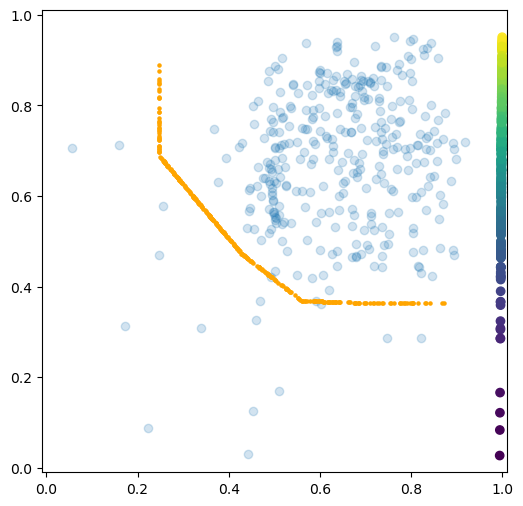

150


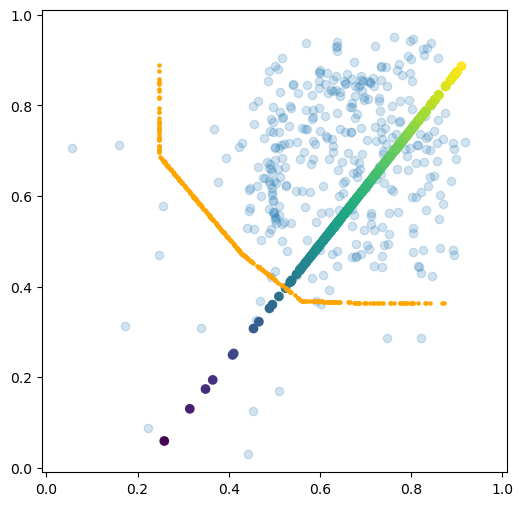

180


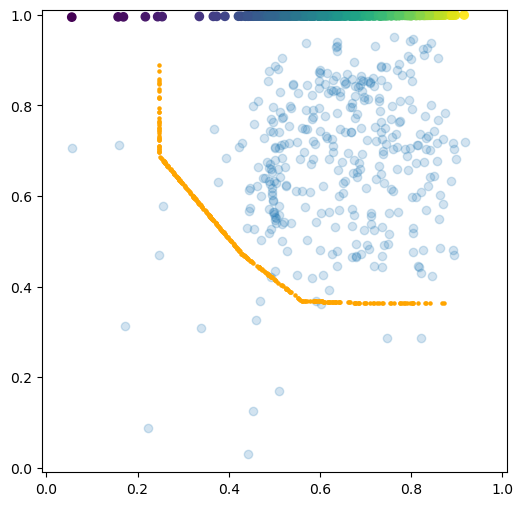

233


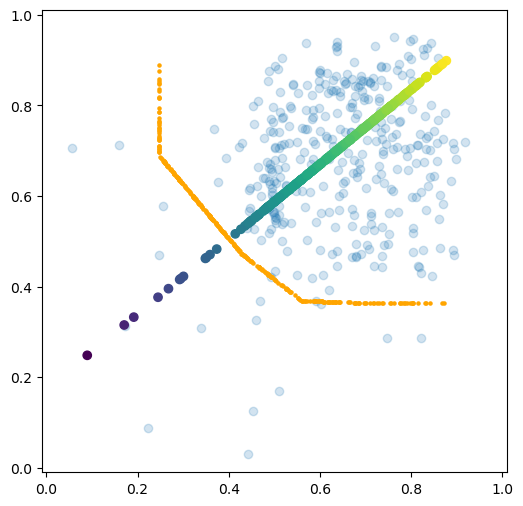

350


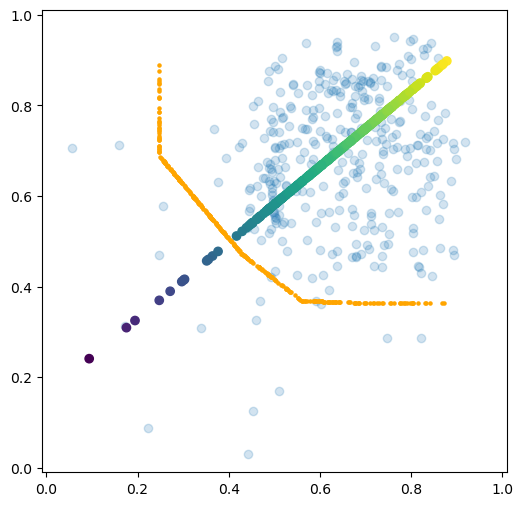

In [9]:
for l in [48, 150, 180, 233, 350]: #75, 96
    print(l)
    score_list_cal_projected = project_u_mv(score_list_cal, U_list[0][l])[0][np.arange(label_list_cal.shape[0]),
                                                    label_list_cal]

    u_theta = U_list[0][l][:,None]
    score_list_cal_projected_vect = (u_theta*score_list_cal_projected).T

    plt.figure(figsize=(6, 6))

    plt.scatter(1-cal_smx_arr[0,:],
                1-cal_smx_arr[1,:], alpha=.2)
    #plt.scatter(1-u_theta[0],
    #            1-u_theta[1])

    plt.scatter(1-score_list_cal_projected_vect[:,0],
                1-score_list_cal_projected_vect[:,1],
                c=np.linalg.norm(1-score_list_cal_projected_vect, axis=1)/np.sqrt(2))

    

    plt.scatter(1-env_list[5][0][0], 
     1-env_list[5][0][1], color='orange', s=5)
    
    #plt.scatter(1-score_list_cal_projected_vect[4,0],
    #            1-score_list_cal_projected_vect[4,1],
    #            c='r')

    plt.xlim(-.01,1.01)
    plt.ylim(-.01,1.01)
    plt.show()

In [ ]:
np.max(U_list[0]@(np.array([score_list_cal[0][np.arange(label_list_cal.shape[0]),label_list_cal][76],
            score_list_cal[1][np.arange(label_list_cal.shape[0]),label_list_cal][76]])[:,None]))

In [ ]:
plt.scatter(cal_smx_arr[0,:],
            cal_smx_arr[1,:], alpha=.2)

plt.scatter(
    env_list[5][0][0], 
    env_list[5][0][1], 
    color='orange', 
    s=5)

plt.scatter(
    (t_list[5][0][1]*score_list_cal[0][
                                np.arange(label_list_cal.shape[0]),
                                label_list_cal
                                ]/t_list[5][0][0]
    )[76],
    (t_list[5][0][1]*score_list_cal[1][
                                np.arange(label_list_cal.shape[0]),
                                label_list_cal
                                ]/t_list[5][0][0]
    )[76]
)

plt.scatter(score_list_cal[0][np.arange(label_list_cal.shape[0]),label_list_cal][76],
            score_list_cal[1][np.arange(label_list_cal.shape[0]),label_list_cal][76],
            c='r')

plt.scatter(U_list[0][150][0],
            U_list[0][150][1])

In [ ]:
t = 1.3
plt.scatter(cal_smx_arr[0,:],
            cal_smx_arr[1,:], alpha=.2)

for l in range(400):
    score_list_cal_projected = project_u_mv(score_list_cal, U_list[0][l])[0][np.arange(label_list_cal.shape[0]),
                                                    label_list_cal]

    u_theta = U_list[0][l][:,None]
    score_list_cal_projected_vect = (u_theta*score_list_cal_projected).T
    plt.scatter(score_list_cal_projected_vect[76,0],
                score_list_cal_projected_vect[76,1],
                c='r')
    
    plt.scatter(u_theta[0]*q_array_list[5][0][l]*t,
                u_theta[1]*q_array_list[5][0][l]*t,
                c='green')
    
plt.scatter(score_list_cal[0][np.arange(label_list_cal.shape[0]),label_list_cal][76],
            score_list_cal[1][np.arange(label_list_cal.shape[0]),label_list_cal][76],
            c='b')
plt.xlim(-0.01,1)
plt.ylim(-0.01,1)

In [ ]:

U_list[0][96]

In [ ]:
plt.hist(t_list[5][0][0])

In [ ]:
np.argmin([project_u_mv(score_list_cal, U_list[0][th,:])[0][np.arange(label_list_cal.shape[0]),label_list_cal]/q for th, q in enumerate(q_array_list[5][0])], 0)


In [ ]:
np.argmax([project_u_mv(score_list_cal, U_list[0][th,:])[0][np.arange(label_list_cal.shape[0]),label_list_cal]/q for th, q in enumerate(q_array_list[5][0])], 0)[76]


In [ ]:
t_list[5][0][0][76], t_list[5][0][1]

In [ ]:
#cal_smx_arr.T@u_theta.flatten()#.shape, u_theta.shape

In [ ]:
#score_list_cal_projected = np.array([(cal_smx_arr[:,i]@u_theta * u_theta)[:,0] for i in range(cal_smx_arr.shape[1])])

In [ ]:
#score_list_cal_projected =((cal_smx_arr.T@u_theta)*u_theta.T)

In [ ]:
data_fig_SI_calibration = pd.DataFrame(1-score_list_cal_projected_vect)
data_fig_SI_calibration.columns = ['IR', 'Raman']
data_fig_SI_calibration['threshold'] = 0
data_fig_SI_calibration.iloc[4,2] = 1
data_fig_SI_calibration.to_csv('results_final/data_fig_SI_calibration_b.csv')
#"data_fig_SI_2_view_Raman.csv"

In [ ]:
q_level1

In [ ]:
n = score_list_cal_projected.shape[0]
q_level1 = np.clip(np.ceil((n+1)*(beta_list[5][0]))/n, 0, 1)
q_level2 = np.clip(np.ceil((n+1)*(1-beta_list[5][0]))/n, 0, 1)

plt.vlines(np.quantile(np.linalg.norm(1-score_list_cal_projected_vect, axis=1)/np.sqrt(2),
            q_level1-0/(1+n)), 0, 80, 'red')

bins_min = np.min(np.linalg.norm(1-score_list_cal_projected_vect, axis=1)/np.sqrt(2))
bins_max = np.max(np.linalg.norm(1-score_list_cal_projected_vect, axis=1)/np.sqrt(2))
bins_list = np.linspace(0, 1, 20) # np.linspace(bins_min, bins_max, 20)

#plt.vlines(1-np.quantile(np.linalg.norm(score_list_cal_projected_vect, axis=1)/np.sqrt(2),
#            q_level2), 0, 80, 'red')
hist_cal_proj = plt.hist(np.linalg.norm(1-score_list_cal_projected_vect, axis=1)/np.sqrt(2), bins=bins_list,density=False)


In [ ]:
pd.DataFrame({'HQI beg bin':hist_cal_proj[1][:-1], 
              'HQI end bin':hist_cal_proj[1][1:], 
              '#':hist_cal_proj[0]
              }).to_csv('results_final/data_fig_SI_calibration_c.csv')

In [ ]:
np.max(np.linalg.norm(1-score_list_cal_projected_vect, axis=1)/np.sqrt(2))

In [ ]:
np.quantile(np.linalg.norm(1-score_list_cal_projected_vect, axis=1)/np.sqrt(2),
            q_level1-0/(1+n))

In [ ]:
np.argmin((np.quantile(np.linalg.norm(score_list_cal_projected_vect, axis=1)/np.sqrt(2),
            q_level2) - np.linalg.norm(score_list_cal_projected_vect, axis=1)/np.sqrt(2))**2)

In [ ]:
np.argmin((np.quantile(np.linalg.norm(1-score_list_cal_projected_vect, axis=1)/np.sqrt(2),
            q_level1-0/(1+n)) - np.linalg.norm(1-score_list_cal_projected_vect, axis=1)/np.sqrt(2))**2)

In [ ]:
np.argsort(np.linalg.norm(1-score_list_cal_projected_vect, axis=1))

In [ ]:
np.argsort(np.linalg.norm(score_list_cal_projected_vect, axis=1))[::-1]

In [ ]:
76

In [ ]:
n = score_list_cal_projected.shape[0]
q_level1 = np.clip(np.ceil((n+1)*(beta_list[5][0]))/n, 0, 1)
q_level2 = np.clip(np.ceil((n+1)*(1-beta_list[5][0]))/n, 0, 1)


plt.vlines(np.quantile(np.linalg.norm(score_list_cal_projected_vect, axis=1)/np.sqrt(2),
            q_level2), 0, 80, 'red')
_ = plt.hist(np.linalg.norm(score_list_cal_projected_vect, axis=1)/np.sqrt(2), bins=np.linspace(.1,.9))

In [ ]:
plt.figure(figsize=(6, 6))

plt.scatter(cal_smx_arr[0,:],
            cal_smx_arr[1,:])
plt.scatter(u_theta[0],
            u_theta[1])

plt.scatter(score_list_cal_projected_vect[:,0],
            score_list_cal_projected_vect[:,1],
            c=score_list_cal_projected)

plt.xlim(-.01,1.01)
plt.ylim(-.01,1.01)

In [ ]:
plt.hist(score_list_cal_projected/np.sqrt(2))

In [ ]:

plt.scatter(1-score_list_cal_projected_vect[:,0],
            1-score_list_cal_projected_vect[:,1])

In [ ]:
plt.hist(np.linalg.norm(1-(1-score_list_cal_projected_vect), axis=1))

In [ ]:
n = score_list_cal_projected.shape[0]
q_level = np.clip(np.ceil((n+1)*(1-beta_list[5][0]))/n, 0, 1)
q_level, np.quantile(score_list_cal_projected, q_level)

In [ ]:
plt.hist(score_list_cal_projected)
plt.vlines(np.quantile(score_list_cal_projected, q_level), 0, 80, color='r')

In [ ]:
np.argsort(cal_smx_arr[1,:])[::]

In [ ]:
beta_list

In [ ]:
j = 108
plt.scatter(cal_smx_arr[0,j],
            cal_smx_arr[1,j])
plt.scatter(u_theta[0],
            u_theta[1])

plt.plot([0,u_theta[0,0]],
         [0,u_theta[1,0]])

plt.scatter(score_list_cal_projected[j,0],
            score_list_cal_projected[j,1])
plt.xlim(0,1)
plt.ylim(0,1)

In [ ]:
score_list[0][~idx_quant][idx][np.arange(label_ir[~idx_quant][idx].shape[0]),
                               label_ir[~idx_quant][idx]] - cal_smx_arr[0]

In [ ]:
h_ir[0]

In [ ]:
h_ir[1]

In [ ]:
h_raman[0]

In [ ]:
cal_data['polymer'] = list(label_table.iloc[label_cal,1])

In [ ]:
cal_data

In [ ]:
# Figure 2

cal_data = pd.DataFrame(1-cal_smx_arr.T)
cal_data.columns = ['IR', 'Raman']

idx_quant,idx = cal_idx_list[5][0]
label_cal = label_ir[~idx_quant][idx]

for i in np.unique(label_cal):

    h_ir = plt.hist(cal_data.iloc[np.where(label_cal==i)[0],0],
                    bins=np.linspace(min_bins, max_bins, 20), 
                    density=False)
    _ = plt.vlines(x= 1-q_ir_list[5][0],
                    ymin=0,
                    ymax=1,
                    colors='red',
                    alpha=1,
                    linestyles='solid',
                    label='95 IR Quantile')
    _ = plt.legend()
    _ = plt.show()

    h_raman = plt.hist(cal_data.iloc[np.where(label_cal==i)[0],1],
                       bins=np.linspace(min_bins, max_bins, 20), 
                       density=False)
    _ = plt.vlines(x=1- q_raman_list[5][0],
                    ymin=0,
                    ymax=1,
                    colors='red',
                    alpha=1,
                    linestyles='solid',
                    label='95 IR Quantile')
    _ = plt.legend()
    _ = plt.show()
    
    print(pd.DataFrame({'HQI init bin':h_ir[1][:-1], 
              'HQI end bin':h_ir[1][1:], 
              '# IR':h_ir[0],
              '# Raman':h_raman[0]
              }))

In [ ]:
# Figure 2

cal_data = pd.DataFrame(1-cal_smx_arr.T)
cal_data.columns = ['IR', 'Raman']


h_ir = plt.hist(1-cal_smx_arr[0],
                bins=np.linspace(min_bins, max_bins, 20), 
                density=False)
_ = plt.vlines(x= 1-q_ir_list[5][0],
                ymin=0,
                ymax=65,
                colors='red',
                alpha=1,
                linestyles='solid',
                label='95 IR Quantile')
_ = plt.legend()
_ = plt.show()

h_raman = plt.hist(1-cal_smx_arr[1],
                   bins=np.linspace(min_bins, max_bins, 20), 
                   density=False)
_ = plt.vlines(x=1- q_raman_list[5][0],
                ymin=0,
                ymax=85,
                colors='red',
                alpha=1,
                linestyles='solid',
                label='95 IR Quantile')
_ = plt.legend()
_ = plt.show()


In [ ]:
1- q_raman_list[5][0], 1-q_ir_list[5][0]

In [ ]:
pd.DataFrame({'HQI init bin':h_ir[1][:-1], 
              'HQI end bin':h_ir[1][1:], 
              '# IR':h_ir[0],
              '# Raman':h_raman[0]
              })

In [ ]:
df_res_all_mean_lis[0]['mvcp']

In [ ]:
q_1, q_2, q_3 = np.quantile(ps_list[5], [.25, .5,.75])

(id_1,
id_2,
id_3) = (np.where(np.array(df_res_all_mean_lis[0]['mvcp']) < q_1)[0][0],
 np.where((np.array(df_res_all_mean_lis[0]['mvcp']) > q_1) & (np.array(df_res_all_mean_lis[0]['mvcp']) < q_3))[0][0],
 np.where(np.array(df_res_all_mean_lis[0]['mvcp']) > q_3)[0][0])


In [ ]:
score_list_true = [score_list[0][np.arange(label_ir.shape[0]),label_ir],
                   score_list[1][np.arange(label_ir.shape[0]),label_ir]]

cal_smx_arr_list = [[score_list_true[0][~x[0]][x[1]], score_list_true[1][~x[0]][x[1]]] for x in cal_idx_list[5]]
cal_smx_arr_list

In [ ]:
_ = plt.boxplot(ps_list[5])

In [ ]:
len(env_list[5])

In [ ]:
len(cal_smx_arr_list)

In [ ]:
plt.scatter(q_ir_list[5], ps_ir_list[5])
plt.scatter(q_ir_list[5], ps_list[5])

In [ ]:
plt.scatter(q_raman_list[5], ps_raman_list[5])
plt.scatter(q_raman_list[5], ps_list[5])

In [ ]:
q_1, q_3

In [ ]:
for id_ in (46, 35, 52):#(id_1, id_2, id_3):
    plt.scatter(1-cal_smx_arr_list[id_][0],
                1-cal_smx_arr_list[id_][1], s=2)

    env_data_list = []
    for env in env_list:
        env_data = pd.DataFrame(1-np.array(env_list[env][id_]).T)
        env_data.columns = ['x - '+str(100-env), 'y - '+str(100-env)]
        _ = plt.plot(env_data['x - '+str(100-env)],
                     env_data['y - '+str(100-env)], label=str(100-env))
        env_data_list.append(env_data)

    q_ir_list, q_raman_list
    _ = plt.vlines(x= 1-q_ir_list[5][id_],
                    ymin=.6,
                    ymax=1,
                    colors='r',
                    alpha=.5,
                    linestyles='solid',
                    label='95 IR Quantile: '+str(round(100*(1-q_ir_list[5][id_]), 2)))

    _ = plt.hlines(y= 1-q_raman_list[5][id_],
                                xmin=.6,
                                xmax=1,
                                colors='purple',
                                alpha=.5,
                                linestyles='solid',
                                label='95 Raman Quantile: '+str(round(100*(1-q_raman_list[5][id_]), 2)))

    _ = plt.legend()
    _ = plt.show()

In [ ]:
for id_ in (46, 35, 52):#(id_1, id_2, id_3):
    #plt.scatter(1-cal_smx_arr_list[id_][0],
    #            1-cal_smx_arr_list[id_][1], s=2)

    env_data_list = []
    for env in env_list:
        env_data = pd.DataFrame(1-np.array(env_list[env][id_]).T)
        env_data.columns = ['x - '+str(100-env), 'y - '+str(100-env)]
        _ = plt.plot(env_data['x - '+str(100-env)],
                     env_data['y - '+str(100-env)], label=str(100-env))
        env_data_list.append(env_data)

    q_ir_list, q_raman_list
    #_ = plt.vlines(x= 1-q_ir_list[5][id_],
    #                ymin=.6,
    #                ymax=1,
    #                colors='r',
    #                alpha=.5,
    #                linestyles='solid',
    #                label='95 IR Quantile: '+str(round(100*(1-q_ir_list[5][id_]), 2)))

    #_ = plt.hlines(y= 1-q_raman_list[5][id_],
    #                            xmin=.6,
    #                            xmax=1,
    #                            colors='purple',
    #                            alpha=.5,
    #                            linestyles='solid',
    #                            label='95 Raman Quantile: '+str(round(100*(1-q_raman_list[5][id_]), 2)))

    _ = plt.legend()
    #_ = plt.show()

In [ ]:
46, 35, 52

In [ ]:
for id_ in np.argsort(ps_list[5]):#range(100):#(id_1, id_2, id_3):
    #if ps_list[5][id_] > q_1:
    #    continue
    print(id_, ps_list[5][id_], ps_ir_list[5][id_], ps_raman_list[5][id_])
    plt.scatter(1-cal_smx_arr_list[id_][0],
                1-cal_smx_arr_list[id_][1], s=2)

    env_data_list = []
    for env in env_list:
        env_data = pd.DataFrame(1-np.array(env_list[env][id_]).T)
        env_data.columns = ['x - '+str(100-env), 'y - '+str(100-env)]
        _ = plt.plot(env_data['x - '+str(100-env)],
                     env_data['y - '+str(100-env)], label=str(100-env))
        env_data_list.append(env_data)

    q_ir_list, q_raman_list
    _ = plt.vlines(x= 1-q_ir_list[5][id_],
                    ymin=.6,
                    ymax=1,
                    colors='r',
                    alpha=.5,
                    linestyles='solid',
                    label='95 IR Quantile: '+str(round(100*(1-q_ir_list[5][id_]), 2)))

    _ = plt.hlines(y= 1-q_raman_list[5][id_],
                                xmin=.6,
                                xmax=1,
                                colors='purple',
                                alpha=.5,
                                linestyles='solid',
                                label='95 Raman Quantile: '+str(round(100*(1-q_raman_list[5][id_]), 2)))

    _ = plt.legend()
    _ = plt.show()

In [ ]:
for id_ in np.argsort(ps_list[5]):#range(100):#(id_1, id_2, id_3):
    #if ps_list[5][id_] > q_1:
    #    continue
    print(ps_list[5][id_])
    plt.scatter(1-cal_smx_arr_list[id_][0],
                1-cal_smx_arr_list[id_][1], color='b', alpha=.05, s=2)

    env_data_list = []
    for env in env_list:
        env_data = pd.DataFrame(1-np.array(env_list[env][id_]).T)
        env_data.columns = ['x - '+str(100-env), 'y - '+str(100-env)]
        _ = plt.plot(env_data['x - '+str(100-env)],
                     env_data['y - '+str(100-env)], color='b', label=str(100-env), alpha=.1)
        env_data_list.append(env_data)

    q_ir_list, q_raman_list
    _ = plt.vlines(x= 1-q_ir_list[5][id_],
                    ymin=.6,
                    ymax=1,
                    colors='r',
                    alpha=.1,
                    linestyles='solid',
                    label='95 IR Quantile: '+str(int(100*(1-q_ir_list[5][id_]))))

    _ = plt.hlines(y= 1-q_raman_list[5][id_],
                                xmin=.6,
                                xmax=1,
                                colors='purple',
                                alpha=.1,
                                linestyles='solid',
                                label='95 Raman Quantile: '+str(int(100*(1-q_raman_list[5][id_]))))

    #_ = plt.legend()
    #_ = plt.show()